# Deep Multi Classifiler

Andrew E. Davidson   
aedavids@ucsc.edu  
Date: 2026-01-22.  
Copyright (c) 2020-2027, Regents of the University of California All rights reserved.  
https://polyformproject.org/licenses/noncommercial/1.0.0  


ref:
* multiClassifier.ipynb

In [1]:
defaultNotebookName="deepMultiClassifiers"

from cliUtilities import configLogging
import logging

# rootLogger = configLogging(logLevel="INFO")
rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-10-15 15:10:54,737 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-10-15 15:10:54,738 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/fagazi/src/python:/private/home/aedavids/fagazi/src/jupyterNotebooks]
2026-10-15 15:10:54,739 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/fagazi/src/python/cliUtilities.py]
2026-10-15 15:10:54,739 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/fagazi/src/jupyterNotebooks]


In [2]:
from IPython.display import display, Markdown
import joblib

import os
os.environ["KERAS_BACKEND"] = "tensorflow"  # "jax" "tensorflow" "torch"
# Note that Keras should only be imported after the backend
# has been configured. The backend cannot be changed once the
# package is imported.
import keras
from keras.callbacks import Callback
from keras.initializers import HeNormal
import keras_tuner as kt

import matplotlib.pyplot as plt
# set up matplotlib default final artwork complient styles
from plots.plotPanel import natureManuscriptStyle
plt.rcParams.update(natureManuscriptStyle)

import numpy as np
import pandas as pd
from pathlib import Path
import pprint
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler
import time

# local imports
from notebookUtils import appendToPYTHONPATH, getNotebookName

ORIG_PYTHONPATH = os.environ['PYTHONPATH']

extraRNA_PythonPath1 = '/private/home/aedavids/extraCellularRNA' 
extraRNA_PythonPath2 = '/private/home/aedavids/extraCellularRNA/src'
appendToPYTHONPATH([extraRNA_PythonPath1, extraRNA_PythonPath2]) 

from archive.dataTypes import  DiagnosticBundle, ModelConfig
from archive.archiveUtilities import is_empty, saveFigure 
from models.mlWorkflow import loadAndSplit

from plots.plotConfusionMatrix import plotConfusionMatrix
from plots.plotROCCurve import plotROCCurve
from plots.sensitivity_at_specificity import computeSensitivitiesAtTargets
from plots.plotUtilities import saveDataFrameImage

from plots.plotPanel import combineFiguresLayout, getSubplotWidthAndHeight, Panel
from plots.plotPanel import displayPDFInNotebook
from plots.plotPanel import setFigureFont

from stats.confusionMatrixUtilities import statistics
from utilities import isOrderedCategoricalSeries

theMeaningOfLife = 42

notebook_start_time = time.time()
print("⏱️ Notebook started.")

I0000 00:00:1792102255.372421 1132689 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-15 15:10:59,702 WARNING notebookUtils.py appendToPYTHONPATH() line:40] [Updated PYTHONPATH: /private/home/aedavids/fagazi/src/python:/private/home/aedavids/fagazi/src/jupyterNotebooks:/private/home/aedavids/extraCellularRNA:/private/home/aedavids/extraCellularRNA/src]


⏱️ Notebook started.


In [3]:
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')
notebookOutDir = f'{notebookDir}/{notebookName}.out'
logger.warning(f'notebookOutDir : {notebookOutDir}')

imgOutDir = f'{notebookOutDir}/img'
os.makedirs(imgOutDir, exist_ok=True)
logger.warning(f'imgOutDir : {imgOutDir}')

imgPanelOutDir = f'{imgOutDir}/panel'
os.makedirs(imgPanelOutDir, exist_ok=True)
logger.warning(f'imgPanelOutDir : {imgPanelOutDir}')

# 9/18/26 reorder confusion matrix to make it easier to compare
# aginst Chen's results
# make it easy to find confusion matrix pdf's for 
# simulation manuscript.
# 
# set this to None to restore default naming
AEDWIP_REORDER_CM_PREFIX = "reorderedCM"
# elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G
# set to None to restore default
AEDWIP_chenCMClassOrder = ['Colorectal_Cancer', 'Stomach_Cancer', 'Liver_Cancer', 'Lung_Cancer', 'Esophagus_Cancer']

2026-10-15 15:10:59,931 WARNING 4221920581.py <module>() line:5] [notebookOutDir : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out]
2026-10-15 15:10:59,932 WARNING 4221920581.py <module>() line:9] [imgOutDir : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img]
2026-10-15 15:10:59,933 WARNING 4221920581.py <module>() line:13] [imgPanelOutDir : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/panel]


notebookName: deepMultiClassifiers
notebookDir: /private/home/aedavids/fagazi/src/jupyterNotebooks


In [4]:
# _G : global use to insure we do not pick up globals in function by accident 
# durring refactoring

simulatedDataRootDir_G = "/private/groups/kimlab/aedavids/fagazi/simulatedData"
scratchDataRootDir_G = "/scratch/aedavids/fagazi/simulatedData"

realDataRoot_G = "/private/groups/kimlab/data/elife"
realDataPath_G = f'{realDataRoot_G}/elife_all_norm_counts_2023-05-18.csv'
realMetaDataPath_G = f'{realDataRoot_G}/elife_scaled_metaData_2023-05-18.csv'

In [5]:
elifeBest20DataSetConfig_G = ModelConfig(
                        dataSetName = "elifeMultiBest20",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{simulatedDataRootDir_G}/elifeGenerate20.sh.out_best20_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        categories = ["Healthy_donor", "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer", "Lung_Cancer", "Stomach_Cancer" ],                       
                    )

elifeBest20DataSetConfig_G.abstract = "used to test refactoring. results should match elifeMultiClassifier.ipynb"


In [6]:
elifeBestShurnk200DataSetConfig_G = ModelConfig(
                        dataSetName = "elifeMultiShurnkBest200",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{simulatedDataRootDir_G}/elifeGenerate200lfcShrink.sh.out_best200_lfcShrink",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results.lfcShrink',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        categories = ["Healthy_donor", "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer", "Lung_Cancer" ], # , "Stomach_Cancer"
                    )

elifeBestShurnk200DataSetConfig_G.abstract = "AEDWIP TODO"


In [7]:

elifeBestShurnk200DropEsophDataSetConfig_G = ModelConfig(
                        dataSetName = "elifeMultiShurnkBest200DropEsoph",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{simulatedDataRootDir_G}/elifeGenerate200lfcShrink.sh.out_best200_lfcShrink",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results.lfcShrink',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        categories = ["Healthy_donor", "Colorectal_Cancer",  
                                        "Liver_Cancer", "Lung_Cancer" , "Stomach_Cancer"], 
                    )
elifeBestShurnk200DropEsophDataSetConfig_G.abstract = "Esop data is bad? only 19 signifigant genes, all the" \
                                                    + " rest have NaN p-values, sensitivity (tpr) = 0.645161 @ 90% Sensitivity (tnr)" \
                                                    + "stomach, liver, and healthy improved, lung dropped, colorectal is unchanges"
                                                    


In [8]:

elifeMultiClassifierSimulatedData_735_lfcShrink_best735_lfcShrink_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierSimulatedData_735_lfcShrink_best735_lfcShrink",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{simulatedDataRootDir_G}/elifeMultiClassifierSimulatedData_735_lfcShrink.sh.out_best735_lfcShrink",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results.lfcShrink',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        categories = ["Healthy_donor", "Colorectal_Cancer", "Esophagus_Cancer",
                                        "Liver_Cancer", "Lung_Cancer", ], # "Stomach_Cancer" 
                    )
                   
logger.error(f'AEDWIP !!!!!!!! abstract ')
elifeMultiClassifierSimulatedData_735_lfcShrink_best735_lfcShrink_G.abstract = "The elifeBest*200* data set features" \
                                        + " where derived from 1vsAll results. 95% of features where derived from Liver Cancer" \
                                            + " This data set is balanced by class and feature. features derived from binary DESeq results"     


2026-10-15 15:10:59,978 ERROR 1599511857.py <module>() line:17] [AEDWIP !!!!!!!! abstract ]


In [9]:
elifeMultiClassifierFrom400Binary_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom400Binary",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom400Binary.sh.out_best400_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        categories = ["Healthy_donor", "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer", "Lung_Cancer", "Stomach_Cancer" ],
                    )

elifeMultiClassifierFrom400Binary_G.abstract = "# src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.ipynb" \
                                        + " demonstrates that using lfc >=2 with padj <= 0.5 produces large numbers" \
                                        + " genes that make good binary classification features" \
                                        + " numFeatures = 1526, nSamples = 304999 "
logger.warning(f'AEDWIP using scratchDataRootDir_G : {scratchDataRootDir_G}')


2026-10-15 15:10:59,990 WARNING 148671263.py <module>() line:21] [AEDWIP using scratchDataRootDir_G : /scratch/aedavids/fagazi/simulatedData]


In [10]:
elifeMultiClassifierFrom400BinaryDropHealthy_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom400BinaryDropHealthy",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom400Binary.sh.out_best400_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        categories = [ "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer", "Lung_Cancer", "Stomach_Cancer" ],
                    )

elifeMultiClassifierFrom400BinaryDropHealthy_G.abstract = "# src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.ipynb" \
                                        + " demonstrates that using lfc >=2 with padj <= 0.5 produces large numbers" \
                                        + " genes that make good binary classification features" \
                                        + " numFeatures = 1526, nSamples = 304999 "
logger.warning(f'AEDWIP using scratchDataRootDir_G : {scratchDataRootDir_G}')
logger.warning(f'We dropped Healthy, sensitivity@Specificity calculations will be incorrect, use macro average sensitivity')

2026-10-15 15:11:00,003 WARNING 2704954290.py <module>() line:21] [AEDWIP using scratchDataRootDir_G : /scratch/aedavids/fagazi/simulatedData]
2026-10-15 15:11:00,003 WARNING 2704954290.py <module>() line:22] [We dropped Healthy, sensitivity@Specificity calculations will be incorrect, use macro average sensitivity]


In [11]:
elifeMultiClassifierFrom400BinaryDropHealthyLung_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom400BinaryDropHealthy+Lung",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom400Binary.sh.out_best400_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sen
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        categories = [ "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer",  "Stomach_Cancer" ],
                    )

In [12]:
elifeMultiClassifierFrom400BinaryDropHealthyStomach_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom400BinaryDropHealthy+Stomach",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom400Binary.sh.out_best400_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        categories = [ "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer",  "Lung_Cancer",  ],
                    )

In [13]:
elifeMultiClassifierFrom300_1vsAllRelaxed_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom300_1vsAllRelaxed",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        categories = [ "Healthy_donor", "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer", "Lung_Cancer", "Stomach_Cancer" ],
                    )

In [14]:
elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        # "Healthy_donor",
                        categories = [  "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer", "Lung_Cancer", "Stomach_Cancer" ],
)

In [15]:
elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthyLung_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy+Lung",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        # "Healthy_donor", "Lung_Cancer",
                        categories = [  "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer",  "Stomach_Cancer" ],
)

# <span style="color:red;">select data set</span>

In [16]:

# runConfig_G = elifeBest20DataSetConfig_G
# runConfig_G = elifeBestShurnk200DropEsophDataSetConfig_G
# runConfig_G = elifeBestShurnk200DataSetConfig_G
# runConfig_G = elifeMultiClassifierSimulatedData_735_lfcShrink_best735_lfcShrink_G

# 6/25/26 runConfig_G = elifeMultiClassifierFrom400Binary_G
# runConfig_G = elifeMultiClassifierFrom400BinaryDropHealthy_G
# runConfig_G = elifeMultiClassifierFrom400BinaryDropHealthyLung_G # used in simulation manuscript
# runConfig_G = elifeMultiClassifierFrom400BinaryDropHealthyStomach_G

# runConfig_G = elifeMultiClassifierFrom300_1vsAllRelaxed_G


runConfig_G = elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G # used in simulation manuscript

# runConfig_G = elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthyLung_G

## Load Training and Validation data sets
They are small just load simulated train, validation, and real test  datasets into memory

In [17]:
%%time
# ROC, sensitivity, specificity, confusion plots expect
# the positive condition to be labeled 1, and the negative
# test results labeled 0.
# make sure categories[0] is the negative diagnostic test class

# diagnosis_G=["Healthy_donor", "Colorectal_Cancer", "Esophagus_Cancer",  
#             "Liver_Cancer", "Lung_Cancer", "Stomach_Cancer" ]

def multiLoad(runConfig : ModelConfig) -> None:
    ''' 
    load training data
    splits into train/validate/test data sets
    initializes the runConfig dataDict
    
     access the data exampe:
        multiDiagnosticBundle = runConfig.dataDict['multi']
        
        multiDiagnosticBundle.simTest.X
    '''
 
    XPath = f"{runConfig.simulatedDataPath}/formatSynthetics.py.out/X.csv"
    yPath = f"{runConfig.simulatedDataPath}/formatSynthetics.py.out/y.csv"
        
    diagnosticBundle = loadAndSplit(
        runConfig.realDataPath,
        runConfig.realMetaDataPath,
        simulatedDataPath=XPath,
        simulatedMetaDataPath=yPath,
        # categories=diagnosis_G,
        categories=runConfig_G.categories
    )
    
    diagnosticBundle.diagnosis = "multi"
    dataDict = dict()
    dataDict['multi'] = diagnosticBundle
    runConfig.dataDict = dataDict
    
multiLoad(runConfig_G)

2026-10-15 15:11:00,086 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results/formatSynthetics.py.out/X.pandas.h5]
2026-10-15 15:11:03,735 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results/formatSynthetics.py.out/y.pandas.h5]
2026-10-15 15:11:07,380 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_all_norm_counts_2023-05-18.csv]
2026-10-15 15:11:09,086 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_scaled_metaData_2023-05-18.csv]


CPU times: user 4.8 s, sys: 4.02 s, total: 8.82 s
Wall time: 9.09 s


In [18]:
# get XTrainDF 
multiDiagnosticBundle = runConfig_G.dataDict['multi']
# added _t to make sure we are using scaled data everwhere
# XTrainDF is not defined any more
XTrainDF_t = multiDiagnosticBundle.simTrain.X
print(f'XTrainDF.shape : {XTrainDF_t.shape}')

# center and scale data
scaler = StandardScaler()
XTrainScaledNP = scaler.fit_transform(XTrainDF_t)

# get y and encode as one hots
yTrainSeries = multiDiagnosticBundle.simTrain.y
assert isOrderedCategoricalSeries(yTrainSeries), "ERROR sensitivity and specific assume he positive condition to be labeled 1, and the negative 0"

# convert to one hots
yTrainOneHotsDF = pd.get_dummies(yTrainSeries, dtype=np.int8 )
print(f'yTrainOneHotsDF.shape : {yTrainOneHotsDF.shape}')
yTrainOneHotsDF.head()

XTrainDF.shape : (132798, 1328)
yTrainOneHotsDF.shape : (132798, 5)


,Colorectal_Cancer,Esophagus_Cancer,Liver_Cancer,Lung_Cancer,Stomach_Cancer
sampleIds,,,,,
s77830,0,1,0,0,0
s204759,0,0,0,1,0
s49168,0,1,0,0,0
s21490,1,0,0,0,0
s228644,0,0,0,0,1


In [19]:
# get validationDF
XValidationDF_t = multiDiagnosticBundle.simVal.X
print(f'XValidationDF.shape : {XValidationDF_t.shape}')
XValidationScaledNP   = scaler.transform(XValidationDF_t)

# get y and encode as one hots
yValidationSeries = multiDiagnosticBundle.simVal.y
assert isOrderedCategoricalSeries(yValidationSeries), "ERROR sensitivity and specific assume he positive condition to be labeled 1, and the negative 0"

# convert to one hots
yValidationOneHotsDF = pd.get_dummies(yValidationSeries, dtype=np.int8 )
print(f'yValidationOneHotsDF.shape : {yValidationOneHotsDF.shape}')
yValidationOneHotsDF.head()

XValidationDF.shape : (44266, 1328)
yValidationOneHotsDF.shape : (44266, 5)


,Colorectal_Cancer,Esophagus_Cancer,Liver_Cancer,Lung_Cancer,Stomach_Cancer
sampleIds,,,,,
s223494,0,0,0,0,1
s192097,0,0,0,1,0
s237559,0,0,0,0,1
s56437,0,1,0,0,0
s22588,1,0,0,0,0


In [20]:
XValidationDF_t.iloc[0:5, 0:10]

Gene,(AAAAG)n,(AGAAGGAGG)n,(AGCCAAGCC)n,(AGGC)n,(ATGAA)n,(ATGTGT)n,(CAGCTC)n,(CCCCG)n,(CCCTTT)n,(CCGCGC)n
sampleIds,,,,,,,,,,
s223494,0.0,-0.032119,2646.000000,-0.038882,153.000000,4.000000,0.0,0.160005,-0.023283,144.369179
s192097,0.0,0.130921,18552.393994,-0.151847,2014.538748,0.321186,0.0,0.142654,0.000000,35.000000
s237559,0.0,0.087279,1048.000000,-0.005846,12.000000,0.000000,19.0,-0.043027,-0.006205,58.890492
s56437,1.0,0.452161,1170.557977,0.061502,35.000000,0.000000,46.0,0.000000,0.000000,53.000000
s22588,0.0,-0.276580,18838.210379,0.003761,25.000000,-0.138315,36.0,0.000000,0.000000,8.000000


In [21]:
XValidationScaledNP[0:5, 0:10]

array([[-0.21505936, -0.21920268, -0.22092336, -0.16331081, -0.03097231,
        -0.14465453, -0.41531815, -0.1396589 , -0.16143534,  1.12864129],
       [-0.21505936, -0.17695568,  0.25811089, -0.16628987,  3.78756047,
        -0.14830416, -0.41531815, -0.14009293, -0.16117593, -0.30942403],
       [-0.21505936, -0.18826435, -0.26904845, -0.16243959, -0.32020246,
        -0.1486228 , -0.22594786, -0.14473764, -0.16124507,  0.0047055 ],
       [-0.19314763, -0.09371534, -0.26535752, -0.16066351, -0.27302307,
        -0.1486228 ,  0.04315729, -0.14366135, -0.16117593, -0.07274697],
       [-0.21505936, -0.28254786,  0.26671849, -0.16218624, -0.29353585,
        -0.14876002, -0.05651128, -0.14366135, -0.16117593, -0.66443962]])

In [22]:
# get XRealDF 
multiDiagnosticBundle = runConfig_G.dataDict['multi']
XRealDF_t = multiDiagnosticBundle.real.X
print(f'XRealDF.shape : {XRealDF_t.shape}')

XRealScaledNP  = scaler.transform(XRealDF_t)


XRealDF.shape : (181, 1328)


## methods

In [23]:
def bestAccuracyLossSummary(history : keras.src.callbacks.history.History
                            ) -> dict[str,float]:
    """
    Return the best training and validation accuracy, the epoch at which
    each occurred, and the corresponding loss values.

    Selection criterion:
        - Best epoch is chosen by MAX accuracy
        - Loss is reported from the SAME epoch

    Returns
    -------
    dict with keys:
        trainBestAccuracy
        trainBestEpoch
        trainLossAtBestAccuracy
        valBestAccuracy
        valBestEpoch
        valLossAtBestAccuracy
    """
    h = history.history

    # handle accuracy vs categorical_accuracy
    accKey = "accuracy" if "accuracy" in h else "categorical_accuracy"
    valAccKey = f"val_{accKey}"

    trainAcc = h[accKey]
    valAcc   = h[valAccKey]

    trainLoss = h["loss"]
    valLoss   = h["val_loss"]

    trainBestIdx = max(range(len(trainAcc)), key=lambda i: trainAcc[i])
    valBestIdx   = max(range(len(valAcc)), key=lambda i: valAcc[i])

    return {
        "trainBestAccuracy": float(trainAcc[trainBestIdx]),
        "trainBestEpoch": trainBestIdx + 1,
        "trainLossAtBestAccuracy": float(trainLoss[trainBestIdx]),
        "valBestAccuracy": float(valAcc[valBestIdx]),
        "valBestEpoch": valBestIdx + 1,
        "valLossAtBestAccuracy": float(valLoss[valBestIdx]),
    }


In [24]:
def buildEarlyStopping(*, patience: int = 10, monitor: str = "val_loss", minDelta: float = 0.0):
    """
    Stop training when the monitored metric stops improving.

    restore_best_weights=True puts the model back to the best epoch at the end.
    
    arguments:
        patience : default = 10
            resonable default if
                validation curves are noise 
                or data set is small, 
                or batch size is modest, 
                or class balance is uneven
    
    ref: https://keras.io/api/callbacks/early_stopping/
    """
    return keras.callbacks.EarlyStopping(
        monitor=monitor,
        patience=patience,
        min_delta=minDelta,
        mode="min" if "loss" in monitor else "max",
        restore_best_weights=True,
        verbose=1,
    )

# <span style="color:red;">buildModel()</span>

In [25]:
def buildModel(nFeatures : int,
               nClasses : int,
               hp : kt.HyperParameters
               ) -> keras.src.models :
    ''' 
    you must set the random seed before calling build model
    
    TODO: AEDWIP:
    use keras hyper parmeter tunning 
    
    arguments 
        nFeatures :
            XTrainDF.shape[1]
            
        nClasses :
            yTrainOneHotsDF.shape[1]
            
    1/24/26
    [64, 32, nClasses] train val accuracy 0.67, early stop @ epoch 168
    try adding more capacity. 
    
    [128, 64, nClasses] train val accuracy 0.61, early stop @ epoch 89
    
    [128, 64, 32 nClasses] train val accuracy 0.70, early stop @ epoch 186

    [128, 64, 32, 16, nClasses] train val accuracy 0.64, early stop @ epoch 275



    '''
    # Define your noise standard deviation
    # Start small (0.01 to 0.1)
    noise_level = 0.05
    
    hp_dropout = hp.Float('dropout_rate', min_value=0.0, max_value=0.5, step=0.1)

    model = keras.Sequential([
        keras.Input(shape=(nFeatures,)),
        
        # ADDED: This adds random "jitter" to your input features
        # only during training!
        # (helps sim-to-real gap)
        keras.layers.GaussianNoise(noise_level),

        # https://keras.io/api/layers/core_layers/dense/
        # dense layers include b -> bias vector (intercept)
        keras.layers.Dense(256, activation="relu", 
                        kernel_initializer=HeNormal(), name="l1"),
        
        # 2. TUNE DROPOUT (The "Robustness" Fixer)
        keras.layers.Dropout(hp_dropout),      
        
        keras.layers.Dense(128, activation="relu", 
                        kernel_initializer=HeNormal(), name="l2"),
        
        keras.layers.Dense(64, activation="relu",
                        kernel_initializer=HeNormal(),  name="l3"),
    
        # bottle neck reduced performance
        # keras.layers.Dense(16, activation="relu",
        #                    kernel_initializer=HeNormal(),  name="l3"),
        
        keras.layers.Dense(32, activation="relu",
                           kernel_initializer=HeNormal(),  name="l4"),        
    
        # keras.layers.Dense(16, activation="relu",
        #                    kernel_initializer=HeNormal(),  name="l4"),
        
        keras.layers.Dense(nClasses, activation="softmax" , 
                        # init defaults to GlorotUniform, Xavier
                        name="output"),
    ])
    
    return model

In [26]:
def calculateAverageSensitvity(
        model : keras.src.models,
        XDF : pd.DataFrame,
        ySeries : pd.Series,
    ) -> tuple[float, pd.DataFrame] :
    ''' 
    macro-average sensitivity (recall) for a multiclass classifier
    
    sensitivity @ specificity is not defined if we do not have a healthy/control class

    Note: this function assumes all 
    
    arguments:
        model
        
        XDF:
            samples to make predictions for
            
        ySeries:
            ground truth labels for XDF 
            
    returns a tuple
        t[1] 
            is the average sensitivity
        
        t[2] 
            is a data frame with index = [tp, fp, fn, tn, sensitivity, specificity]
            columns are class ids

    '''
    yPredictionSeries = makePredictions(model, XDF, ySeries)
    confusionMatrixNP = confusion_matrix(ySeries, yPredictionSeries, labels=ySeries.cat.categories)
    # print(confusionMatrixNP)
    statsDict = statistics(confusionMatrixNP, ySeries.cat.categories)
    # print(pprint.pformat(statsDict, sort_dicts=False))
    
    retDF  = pd.DataFrame(statsDict)
    # display(df)
    
    nClasses = len(ySeries.cat.categories)
    # averageSensitivity = retDF.loc['sensitivity', :].sum() / nClasses
    averageSensitivity = retDF.loc['sensitivity', :].mean()
    
    # print(df.index)
    # print(averageSensitivity)
    # print(averageSensitivity.sum())
    
    return( (averageSensitivity, retDF) )

In [27]:
def calculateSensitivitiesAtTargets(
        model : keras.src.models,
        XScaled : pd.DataFrame,
        ySeries : pd.Series,
        specifityTargets : list[float ]= [0.9],
    ) -> pd.DataFrame :
    '''
    Docstring for hack
    
    TODO refactor see plots.sensitivity_at_specificity.computeSensitivitiesAtTargets   
    
    assume all models are multi classifiers
    
    returns a data frame with columns
    ['diagnosis', 'Sensitivity (TPR)', 'Target Specificity', 'Achieved Specificity (TNR)',	'Approx. Threshold','auc']

    '''
    
    if not isOrderedCategoricalSeries(ySeries):
            errMsg = f'argument ySeries {type(ySeries)} expected pandas series with an ordered categorical dtype'
            logger.error(errMsg)
            raise TypeError(errMsg)
        
    retDF = pd.DataFrame()
    
    # get soft max probabilties
    predictedProbsNP = model.predict(XScaled, verbose=0)
    
    yPredClass = np.argmax(predictedProbsNP, axis=-1)
    nClasses = len(ySeries.cat.categories)
    yPredOneHotNP = np.eye(nClasses)[yPredClass]

    # encode ground true labels into one hot format
    yOneHotsDF = pd.get_dummies(ySeries, dtype=np.int8 )
    
    mClasses = yValidationSeries.cat.categories
    for classIdx, diagnosis in enumerate(mClasses) :
        yTrue = yOneHotsDF.iloc[:, classIdx]
        yScore   = yPredOneHotNP[:, classIdx]  

        t = computeSensitivitiesAtTargets(
                                yTrue,
                                yScore,
                                targets=specifityTargets,
                                interpolate=True
                                )

        senitivityAtSpecificityDF, points = t
        senitivityAtSpecificityDF['diagnosis'] = diagnosis
        
        retDF = pd.concat([retDF, senitivityAtSpecificityDF]).reset_index(drop=True)
    
    retDF = retDF.loc[:, ['diagnosis', 'Sensitivity (TPR)', 'Target Specificity', 'Achieved Specificity (TNR)', 'auc' ]]
    return retDF


In [28]:
def convertNumpyToCategorical(
    predictionsNP : np.array,
    ySeries : pd.Series,
    ):
    ''' 
    converts a numpy array of integers to a series
    matching the categories and ordering from ySeries
    '''
    
    yPred = pd.Series(
                pd.Categorical.from_codes(
                                        codes=predictionsNP,
                                        categories=ySeries.cat.categories,
                                        ordered=ySeries.cat.ordered
                                        ),
                index=ySeries.index[:len(predictionsNP)]
    )
    
    return yPred

In [29]:
def makePredictions(
        model : keras.src.models,
        XDF : pd.DataFrame,
        ySeries : pd.Series,
    ) -> pd.Series:
    ''' 
    makes predictions and returns  series
    matching the categories and ordering from ySeries
    
    arguments:
    model
    
    XDF:
        samples to make predictions for
        
    ySeries:
        ground truth labels for XDF 
    '''
    # 1) one hot probabilities (nSamples, nClasses)
    probsNP = model.predict(XDF, verbose=0)

    # 2) convert 1 hots a single class index per sample (nSamples,)
    predClassIdxNP = probsNP.argmax(axis=1)
    
    yPredictionsSeries = convertNumpyToCategorical(predClassIdxNP , ySeries)
    
    return yPredictionsSeries


In [30]:
def makeSensAtSpecMetric(classIdx : int , specificity : float) -> keras.metrics.Metric:
    ''' 
    SensitivityAtSpecificity assumes binary classification
    Use classIdx to mark positive class
    '''
    print(f'AEDWIP classIdx : {classIdx} specificity : {specificity}')
    return keras.metrics.SensitivityAtSpecificity(
        specificity=specificity,
        class_id=classIdx,
        num_thresholds=200,
        name=f"sensAtSpec{int(specificity*100)}_c{classIdx}"
    )

In [31]:
def buildSensAtSpecMetrics(nClasses : int, 
        refTargetSpecificity : float, 
        targetSpecificity : float) -> list[keras.metrics.Metric]:
    ''' print('')
    '''
    retMetrics = list() 
    for i in range(0, nClasses):
        for specificity in [refTargetSpecificity, targetSpecificity] :
            retMetrics.append( makeSensAtSpecMetric(classIdx=i , specificity=specificity))
            
    return retMetrics


In [32]:
def plotCM(
        model : keras.src.models,
        XDF : pd.DataFrame,
        ySeries : pd.Series,
        title : str,
        newClassOrder : list[str] = None
    ) -> plt.Figure :
    '''
    1. calls model.predict
    2. convert predictions to labels
    3. plots a confusion matrix
    
    arguments:
        model
        
        XDF:
            samples to make predictions for
            
        ySeries:
            ground truth labels for XDF 
            
        newClassOrder
            default = None
            
            9/17/26 reorder the confusion matrix to make it easier
            to compare our cm against Chen's results in simulation manuscript
                    
    '''
    yPredictionsSeries = makePredictions(model, XDF, ySeries)
    retFig = plotCMImpl( ySeries, yPredictionsSeries, title, newClassOrder)
    return retFig

In [33]:
def plotCMImpl(
    ySeries : pd.Series,
    predictions : np.array,
    title : str,
    newClassOrder : list[str] = None
    ) -> plt.Figure:
    '''
    private function 
    based on src/python/models/mlWorkflow.py evaluate()
    
    see plotCM()
    
    arguments :
        ySeries : 
            ground trueth
            
        predictions : 
            made by model
            
        newClassOrder
            default = None
            
            9/17/26 reorder the confusion matrix to make it easier
            to compare our cm against Chen's in simulation manuscript
            
    returns
        plt.Figure
    ''' 
    if not isOrderedCategoricalSeries(ySeries):
            errMsg = f'argument ySeries {type(ySeries)} expected pandas series with an ordered categorical dtype'
            logger.error(errMsg)
            raise TypeError(errMsg)
        
    # confusionMatrixPrecentageNP, disp = plotConfusionMatrix(ySeries.cat.categories, 
    #                                         ySeries,
    #                                         predictions,
    #                                         title,
    #                                         displayAsPrecentage=True)
    
    labels = ySeries.cat.categories
    if newClassOrder is not None:
        labels = newClassOrder
        
        # Ensure this is a reordering of all existing categories.
        assert len(labels) == len(ySeries.cat.categories),  \
                "newClassOrder must have the same number of categories"
                
        print(f'ySeries.cat.categories : {ySeries.cat.categories}'), \
                "newClassOrder must contain exactly the existing categories"
        
        logger.warning(f'labels                 : {labels}')
        logger.warning(f'ySeries.cat.categories : {ySeries.cat.categories}')
        assert set(labels) == set(ySeries.cat.categories)
        
    confusionMatrixPrecentageNP, disp = plotConfusionMatrix(labels, 
                                            ySeries,
                                            predictions,
                                            title,
                                            displayAsPrecentage=True)    
   
    # confusionMatrix = confusion_matrix(ySeries, predictions, labels=ySeries.cat.categories)
    confusionMatrix = confusion_matrix(ySeries, predictions, labels=labels)
    
    fig = disp.figure_
    return fig
        

In [34]:
def plotTrainingCurves(history : keras.src.callbacks.history.History) -> plt.figure:
    """
    Plot training and validation loss and accuracy from a Keras History object.
    """
    historyDict = history.history
    epochs = range(1, len(historyDict["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # ---- Loss ----
    axes[0].plot(epochs, historyDict["loss"], label="Train Loss")
    axes[0].plot(epochs, historyDict["val_loss"], label="Val Loss")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    # ---- Accuracy ----
    accKey = "accuracy" if "accuracy" in historyDict else "categorical_accuracy"
    valAccKey = f"val_{accKey}"

    axes[1].plot(epochs, historyDict[accKey], label="Train Accuracy")
    axes[1].plot(epochs, historyDict[valAccKey], label="Val Accuracy")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()
    return fig

In [35]:
def prettyPrintDictRounded(d: dict, *, decimals: int = 3) -> str:
    """
    Pretty-print a dict, rounding float values to a fixed number of decimals.
    """
    def roundValue(v):
        if isinstance(v, float):
            return round(v, decimals)
        return v

    roundedDict = {k: roundValue(v) for k, v in d.items()}
    ret = pprint.pformat(roundedDict, sort_dicts=False)
    return ret

In [36]:
def setRandomSeed(seed: int=theMeaningOfLife):
    """
    Set random seed using Keras utilities.
    Covers Python, NumPy, and TensorFlow RNGs.
    """
    os.environ["PYTHONHASHSEED"] = str(seed)
    keras.utils.set_random_seed(seed)

In [37]:
class StopOnMeanMetric(Callback):
    ''' 
    generated by chatGPT
    
    Keras’ built-in EarlyStopping can only monitor one metric, not a 
    computed aggregate like the mean across several metrics.
    '''
    def __init__(self, metricPrefix: str, nClasses: int, threshold: float):
        super().__init__()
        self.metricPrefix = metricPrefix
        self.nClasses = nClasses
        self.threshold = threshold

    def on_epoch_end(self, epoch: int, logs: dict | None = None) -> None:
        logs = logs or {}

        values = []
        for i in range(self.nClasses):
            key = f"val_{self.metricPrefix}_c{i}"
            if key in logs:
                values.append(logs[key])

        if len(values) == self.nClasses:
            meanVal = float(np.mean(values))

            print(f"\nmean {self.metricPrefix}: {meanVal:.4f}")

            if meanVal >= self.threshold:
                print(
                    f"\nStopping training: mean {self.metricPrefix} "
                    f"{meanVal:.4f} >= {self.threshold}"
                )
                self.model.stop_training = True

# <span style="color:red;background-color:yellow;">Train Deep Multi Classifier</span>

## learning curve overview

Train ↓, Val ↓ → learning

Train ↓, Val ↑ → overfitting

Both flat → underfitting or LR too small

Noisy curves → batch size too small or LR too high




###################### learning rate : 1e-05
AEDWIP classIdx : 0 specificity : 0.2
AEDWIP classIdx : 0 specificity : 0.9
AEDWIP classIdx : 1 specificity : 0.2
AEDWIP classIdx : 1 specificity : 0.9
AEDWIP classIdx : 2 specificity : 0.2
AEDWIP classIdx : 2 specificity : 0.9
AEDWIP classIdx : 3 specificity : 0.2
AEDWIP classIdx : 3 specificity : 0.9
AEDWIP classIdx : 4 specificity : 0.2
AEDWIP classIdx : 4 specificity : 0.9


E0000 00:00:1792102273.946283 1132689 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/10
260/260 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.5155 - loss: 1.2705 - sensAtSpec20_c0: 0.9994 - sensAtSpec20_c1: 0.9787 - sensAtSpec20_c2: 0.8965 - sensAtSpec20_c3: 0.9865 - sensAtSpec20_c4: 0.9997 - sensAtSpec90_c0: 0.4249 - sensAtSpec90_c1: 0.6846 - sensAtSpec90_c2: 0.7075 - sensAtSpec90_c3: 0.2543 - sensAtSpec90_c4: 0.4233 - val_accuracy: 0.7845 - val_loss: 0.6961 - val_sensAtSpec20_c0: 1.0000 - val_sensAtSpec20_c1: 1.0000 - val_sensAtSpec20_c2: 1.0000 - val_sensAtSpec20_c3: 1.0000 - val_sensAtSpec20_c4: 0.9998 - val_sensAtSpec90_c0: 0.7808 - val_sensAtSpec90_c1: 0.9911 - val_sensAtSpec90_c2: 0.9979 - val_sensAtSpec90_c3: 0.8732 - val_sensAtSpec90_c4: 0.9160
Epoch 2/10
260/260 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8984 - loss: 0.4572 - sensAtSpec20_c0: 0.9998 - sensAtSpec20_c1: 0.9999 - sensAtSpec20_c2: 1.0000 - sensAtSpec20_c3: 1.0000 - sensAtSpec20_c4: 0.9998 - sensAtSpec90_c0: 0.9456 - sensAtSpec90_c1: 0.9991 - sensAtSpec90_c2: 0.9996 - sensAtSpec90_c

```python
{'trainBestAccuracy': 0.99939,
 'trainBestEpoch': 10,
 'trainLossAtBestAccuracy': 0.00827,
 'valBestAccuracy': 0.99934,
 'valBestEpoch': 10,
 'valLossAtBestAccuracy': 0.0074,
 'learningRate': 1e-05}
```

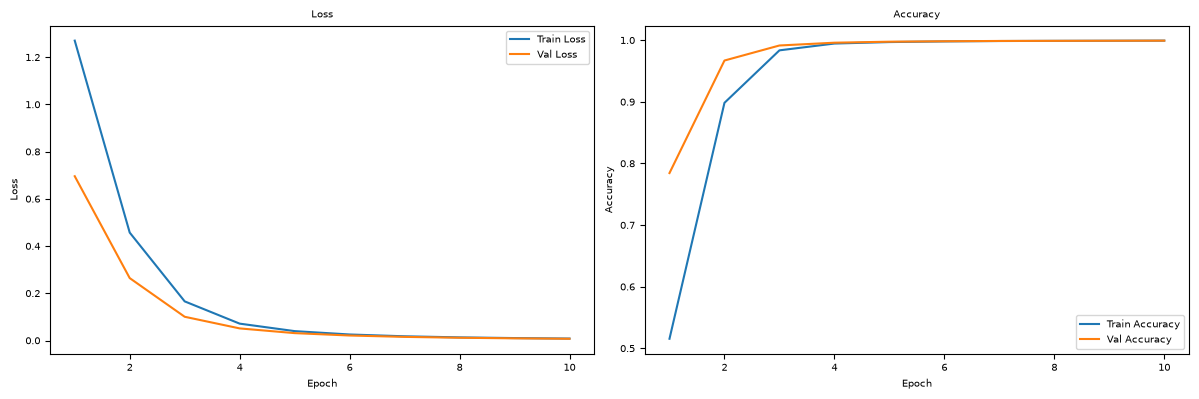

2026-10-15 15:11:49,897 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/learningCurve_learning-curves-deep-mulit-real-elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy.png]
2026-10-15 15:11:50,611 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/learningCurve_learning-curves-deep-mulit-real-elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy.pdf]
2026-10-15 15:11:53,534 WARNING 287088127.py plotCMImpl() line:51] [labels                 : ['Colorectal_Cancer', 'Stomach_Cancer', 'Liver_Cancer', 'Lung_Cancer', 'Esophagus_Cancer']]
2026-10-15 15:11:53,535 WARNING 287088127.py plotCMImpl() line:52] [ySeries.cat.categories : Index(['Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer', 'Lung_Cancer',
       'Stomach_Cancer'],
      dtype='str')]


ySeries.cat.categories : Index(['Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer', 'Lung_Cancer',
       'Stomach_Cancer'],
      dtype='str')


2026-10-15 15:11:54,884 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/reorderedCM_validationCMCurve_validation-data-set-deep-mulit-real-elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy.png]
2026-10-15 15:11:55,811 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/reorderedCM_validationCMCurve_validation-data-set-deep-mulit-real-elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy.pdf]


## Simulated Validation data set

,diagnosis,Sensitivity (TPR),Target Specificity,Achieved Specificity (TNR),auc
0,Colorectal_Cancer,0.998475,0.9,0.9,0.998998
1,Esophagus_Cancer,1.000000,0.9,0.9,0.999958
2,Liver_Cancer,1.000000,0.9,0.9,1.000000
3,Lung_Cancer,0.999797,0.9,0.9,0.999831
4,Stomach_Cancer,0.998780,0.9,0.9,0.999167


Model: "sequential"

... (2 outputs left out)

 Trainable params: 383,621 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 767,244 (2.93 MB)

CPU times: user 11min 36s, sys: 3min 52s, total: 15min 29s
Wall time: 44.5 s


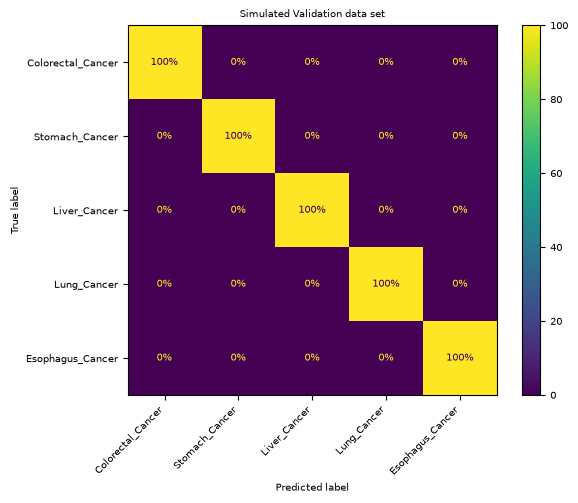

In [38]:
%%time

bestLearningRate = 1e-5 
learningRates = [bestLearningRate] #[3e-5] #[1e-5] #[1e-5, 3e-5] #[1e-4, 3e-4] # e-3 is to big, 1e-3, 3e-3]
results = [1e-5]


# Evaluate TPR at spec=0.90 (target) and spec≈0.167 (chance level for 6 balanced classes).
# Helps check whether the model is learning above random baseline.

nClasses = len(runConfig_G.categories)
refTargetSpecificity = 1.0 / nClasses
# refSensitivityMetricName = f'sensitivityAt{refTargetSpecificity * 100}%'

targetSpecificity = 0.9
# sensitivityMetricName = f'sensitivityAt{targetSpecificity * 100}%'

for learningRate  in learningRates:
    print(f"\n\n\n###################### learning rate : {learningRate}")
    
    # you must set the random seed before calling build model
    # to get reproducable results
    setRandomSeed()
    model = buildModel(nFeatures=XTrainScaledNP.shape[1], 
                       nClasses=yTrainOneHotsDF.shape[1],
                       hp=kt.HyperParameters()
                       )

    model.compile(
        # https://keras.io/api/optimizers/adam/
        # optimizer="adam",
        optimizer=keras.optimizers.Adam(learning_rate=learningRate),
        loss="categorical_crossentropy",
        
        # https://keras.io/api/metrics/classification_metrics/#specificityatsensitivity-class
        # "categorical_accuracy" https://keras.io/api/metrics/accuracy_metrics/#accuracy-class
        # accuracy will do the "right thing" depending on the shape of Y. ie if onehot 
        # will use categorical_accuracy,
        metrics=["accuracy"] \
            + buildSensAtSpecMetrics(nClasses, refTargetSpecificity, targetSpecificity) ,
    )
    
    # 3/5/26, I think we are over fitting
    # from from first epoc might be good enough
    callbacks = [
        # use early stopping 
        # It keeps improving even when accuracy plateaus, and it 
        # reacts early when the model starts to overfit.
        buildEarlyStopping(patience=20, monitor="val_loss"),
    ]
    
    # we only run for 1 epoc
    # callbacks = StopOnMeanMetric(
    #         metricPrefix="sensAtSpec90",
    #         nClasses=nClasses,
    #         threshold=0.9
    #     )
    
    # https://keras.io/api/models/model_training_apis/
    history = model.fit(
        #XTrain.values,
        XTrainScaledNP,
        yTrainOneHotsDF.values,
        #validation_data=(XValidationDFScaled.values, yValidationOneHotsDF.values),
        validation_data=(XValidationScaledNP, yValidationOneHotsDF.values),
        
        # we want to use a larger number of epochs so that we can
        # see if the learn rate is to large. ie. loss or accuracy is diverging
        # you may need to turn buildEarlyStopping off
        #epochs=10, #400, #200, #100, #160, #80, #40, #10, #20, # 10,
        epochs=10, #50, #40, #30, #20, 
        batch_size=512, #2048, #1024, #512, #256, #32,
        callbacks=callbacks,
        #verbose=1, # default is 1 line per epoch, 0 = silent, 1 or 2 is one line per epoch
    )
        
    bestSummaryDict = bestAccuracyLossSummary(history)
    bestSummaryDict["learningRate"] = learningRate
    results.append(bestSummaryDict)
    
    # decimals = 5 becuase learning rates are small
    niceStr = prettyPrintDictRounded( bestSummaryDict, decimals=5 )
    display(Markdown(f"```python\n{niceStr}\n```"))
    
    learningCurveFigTitle = f"learning curves deep mulit real  {runConfig_G.dataSetName}"
    learningCurveFig = plotTrainingCurves( history )
    saveFigure(learningCurveFig, learningCurveFigTitle, imgOutDir, prefix="learningCurve")

    validationCMFigTitle =  f"validation data set deep mulit real  {runConfig_G.dataSetName}"
    validationCMFig = plotCM(model,
                        XValidationScaledNP, 
                        yValidationSeries,
                        title="Simulated Validation data set",
                        newClassOrder=AEDWIP_chenCMClassOrder
                        )
    
    aedwipPrefix = f'{AEDWIP_REORDER_CM_PREFIX}_validationCMCurve'
    # saveFigure(validationCMFig, validationCMFigTitle, imgOutDir, prefix="validationCMCurve")
    saveFigure(validationCMFig, validationCMFigTitle, imgOutDir, prefix=aedwipPrefix)
    

    display(Markdown('## Simulated Validation data set'))
    senitivityAtSpecificityDF = calculateSensitivitiesAtTargets(model=model, 
                                                                XScaled=XValidationScaledNP, 
                                                                ySeries=yValidationSeries)
    display(senitivityAtSpecificityDF)

model.summary()

In [39]:
for k in history.history.keys():
    print(k)
 
# targetSpecificity = 0.9
   
# f'sensitivityAt{targetSpecificity * 100}%'

# len(runConfig_G.categories)

# ['a', 'b'] + [1, 2]

# for i in range(0,5):
#     print(i)

print(f"val_accuracy'][0:5]        {np.round( history.history['val_accuracy'][0:5], 3 )}")
# print(f"val_sensAtSpec20_c0'][0:5] {np.round( history.history['val_sensAtSpec20_c0'][0:5], 3) }")
print(f"val_sensAtSpec90_c0_1      {np.round( history.history['val_sensAtSpec90_c0'][0:5], 3)}" )

accuracy
loss
sensAtSpec20_c0
sensAtSpec20_c1
sensAtSpec20_c2
sensAtSpec20_c3
sensAtSpec20_c4
sensAtSpec90_c0
sensAtSpec90_c1
sensAtSpec90_c2
sensAtSpec90_c3
sensAtSpec90_c4
val_accuracy
val_loss
val_sensAtSpec20_c0
val_sensAtSpec20_c1
val_sensAtSpec20_c2
val_sensAtSpec20_c3
val_sensAtSpec20_c4
val_sensAtSpec90_c0
val_sensAtSpec90_c1
val_sensAtSpec90_c2
val_sensAtSpec90_c3
val_sensAtSpec90_c4
val_accuracy'][0:5]        [0.784 0.967 0.992 0.996 0.998]
val_sensAtSpec90_c0_1      [0.781 0.994 0.999 1.    1.   ]


## <span style="color:red;background-color:yellow"> real data performance</span>

2026-10-15 15:11:58,753 ERROR 3323353736.py <module>() line:1] [AEDWIP TODO do not run till hypertunning is complete]
2026-10-15 15:11:58,888 WARNING 287088127.py plotCMImpl() line:51] [labels                 : ['Colorectal_Cancer', 'Stomach_Cancer', 'Liver_Cancer', 'Lung_Cancer', 'Esophagus_Cancer']]
2026-10-15 15:11:58,889 WARNING 287088127.py plotCMImpl() line:52] [ySeries.cat.categories : Index(['Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer', 'Lung_Cancer',
       'Stomach_Cancer'],
      dtype='str')]


ySeries.cat.categories : Index(['Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer', 'Lung_Cancer',
       'Stomach_Cancer'],
      dtype='str')


2026-10-15 15:11:59,867 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/reorderedCM_confusionMatrix_deep-mulit-real-elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy.png]
2026-10-15 15:12:00,861 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/reorderedCM_confusionMatrix_deep-mulit-real-elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy.pdf]


'/private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/reorderedCM_confusionMatrix_deep-mulit-real-elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy.png'

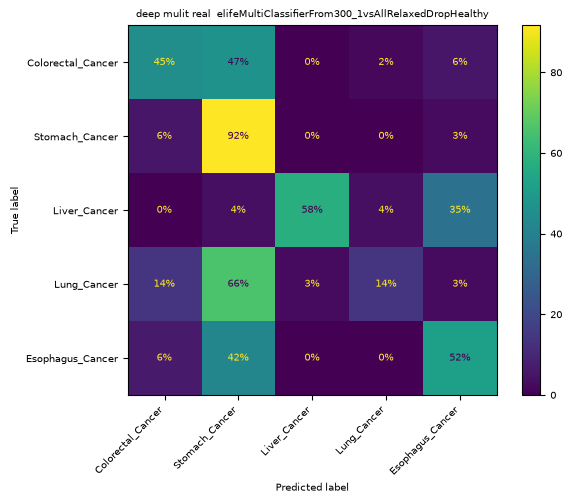

In [40]:
logger.error(f'AEDWIP TODO do not run till hypertunning is complete')
# get y and encode as one hots
yRealSeries = multiDiagnosticBundle.real.y
assert isOrderedCategoricalSeries(yRealSeries), "ERROR sensitivity and specific assume he positive condition to be labeled 1, and the negative 0"

realCMFigTitle = f"deep mulit real  {runConfig_G.dataSetName}" 
realCMFig = plotCM(model,
                    #XRealDF, 
                    XRealScaledNP,
                    yRealSeries,
                    title=realCMFigTitle,
                    newClassOrder=AEDWIP_chenCMClassOrder
                    )

aedwipPrefix = f'{AEDWIP_REORDER_CM_PREFIX}_confusionMatrix'
# saveFigure(realCMFig, realCMFigTitle, imgOutDir, prefix="confusionMatrix")
saveFigure(realCMFig, realCMFigTitle, imgOutDir, prefix=aedwipPrefix)

In [41]:
# from pdb import run


realSenitivityAtSpecificityDF = calculateSensitivitiesAtTargets(model=model, 
                                                                XScaled=XRealScaledNP, 
                                                                ySeries=yRealSeries)
# use to_markdown so we can copy results in to dicussion markdown cell
display(Markdown(realSenitivityAtSpecificityDF.to_markdown(index=False)))

print(f'{runConfig_G.dataSetName}\naverage real sensitivity @ 90% specificity {realSenitivityAtSpecificityDF['Sensitivity (TPR)'].mean().round(2)=}')

| diagnosis         |   Sensitivity (TPR) |   Target Specificity |   Achieved Specificity (TNR) |      auc |
|:------------------|--------------------:|---------------------:|-----------------------------:|---------:|
| Colorectal_Cancer |            0.470303 |                  0.9 |                          0.9 | 0.691259 |
| Esophagus_Cancer  |            0.519687 |                  0.9 |                          0.9 | 0.711398 |
| Liver_Cancer      |            0.616758 |                  0.9 |                          0.9 | 0.785236 |
| Lung_Cancer       |            0.217857 |                  0.9 |                          0.9 | 0.564579 |
| Stomach_Cancer    |            0.214382 |                  0.9 |                          0.9 | 0.74454  |

elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy
average real sensitivity @ 90% specificity realSenitivityAtSpecificityDF['Sensitivity (TPR)'].mean().round(2)=np.float64(0.41)


,diagnosis,Sensitivity (TPR)
0,Colorectal_Cancer,0.470303
1,Esophagus_Cancer,0.519687
2,Liver_Cancer,0.616758
3,Lung_Cancer,0.217857
4,Stomach_Cancer,0.214382


2026-10-15 15:12:01,448 WARNING plotUtilities.py saveDataFrameImage() line:204] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/realSenitivityAt90PercentSpecificity.png]
2026-10-15 15:12:01,575 WARNING plotUtilities.py saveDataFrameImage() line:207] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/realSenitivityAt90PercentSpecificity.pdf]


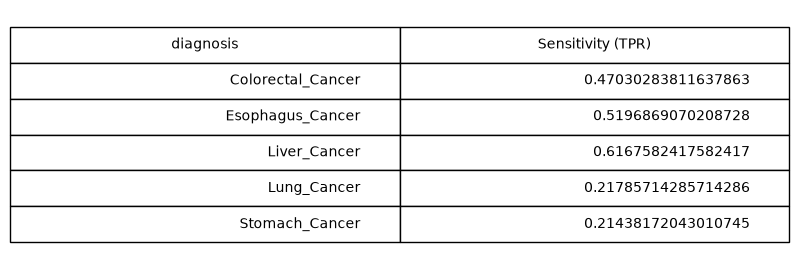

In [42]:
realSenitivityAt90PercentSpecificityDF= realSenitivityAtSpecificityDF.loc[:, ['diagnosis', 'Sensitivity (TPR)']]
display( realSenitivityAt90PercentSpecificityDF )

realSenitivityAt90PercentSpecificityDFPath = f'{imgOutDir}/{runConfig_G.dataSetName}/realSenitivityAt90PercentSpecificity.png'
saveDataFrameImage(realSenitivityAt90PercentSpecificityDF,realSenitivityAt90PercentSpecificityDFPath, showIndex=False )

In [43]:
t = calculateAverageSensitvity(model, XRealScaledNP, yRealSeries,)
averageRealSensitivity, realStatDF = t

print(f'{runConfig_G.dataSetName} real stat DF')
display(realStatDF)

print(f'***\naverage real sensitivity : {averageRealSensitivity}\n****')

elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy real stat DF


,Colorectal_Cancer,Esophagus_Cancer,Liver_Cancer,Lung_Cancer,Stomach_Cancer
tp,24.000000,16.000000,15.000000,5.000000,33.000000
fp,9.000000,14.000000,1.000000,2.000000,62.000000
fn,29.000000,15.000000,11.000000,30.000000,3.000000
tn,119.000000,136.000000,154.000000,144.000000,83.000000
sensitivity,0.452830,0.516129,0.576923,0.142857,0.916667
specificity,0.929688,0.906667,0.993548,0.986301,0.572414


***
average real sensitivity : 0.5210812214768392
****


In [44]:
from collections.abc import Sequence
import numpy as np
import pandas as pd


class KerasClassifierAdapter:
    '''
    Adapter that provides a scikit-learn-like interface for a Keras
    multiclass classifier.

    Assumes the Keras model uses a softmax output layer and that classNames
    are in the same order as the model's output neurons.
    '''

    def __init__(
            self,
            kerasModel,
            classNames: Sequence[str],
        ) -> None:

        self.kerasModel = kerasModel
        self.classes_ = np.asarray(classNames)


    def predict_proba(
            self,
            XDF: pd.DataFrame,
        ) -> np.ndarray:

        predictedProbability = self.kerasModel.predict(
            XDF,
            verbose=0
        )

        if predictedProbability.ndim != 2:
            raise ValueError(
                f'Expected 2-D Keras output, got shape '
                f'{predictedProbability.shape}'
            )

        if predictedProbability.shape[1] != len(self.classes_):
            raise ValueError(
                f'Keras model predicts {predictedProbability.shape[1]} '
                f'classes but {len(self.classes_)} class names were provided'
            )

        return predictedProbability

2026-10-15 15:12:02,731 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/roc_deep-mulit-real-elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy.png]
2026-10-15 15:12:03,337 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/roc_deep-mulit-real-elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy.pdf]


'/private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/roc_deep-mulit-real-elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy.png'

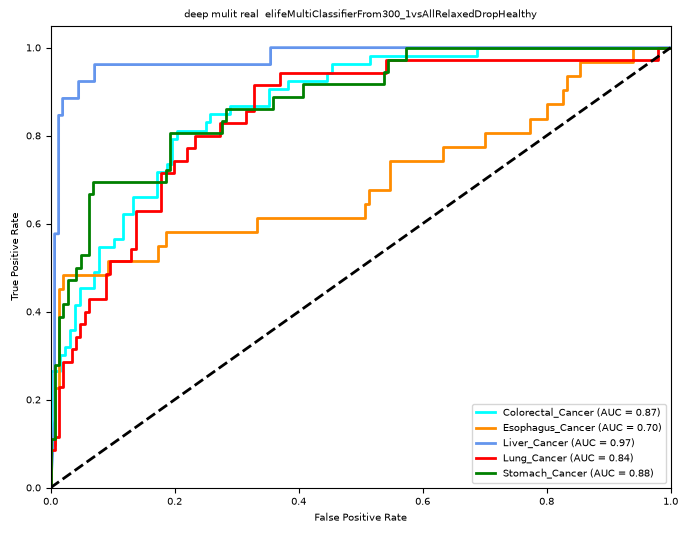

In [45]:
realROCFigTitle = f"deep mulit real  {runConfig_G.dataSetName}" 

kerasAdapterModel = KerasClassifierAdapter(
    kerasModel=model,
    classNames=yRealSeries.cat.categories
)

rocPlotFig, rocPlotAx, aucDict = plotROCCurve(
    model=kerasAdapterModel, #model,
    #aedwip labelEncoder=labelEncoder,
    XDF=XRealScaledNP ,
    #y=y,
    ySeries=yRealSeries,
    title=realROCFigTitle,
    #binaryPositiveLabel='Healthy_donor'
    )
    

saveFigure(rocPlotFig, realROCFigTitle, imgOutDir, prefix="roc")

# <span style="color:red;background-color:yellow;">10/6/26 Save the trained model for use in another notebook to generate final manuscript artwork.</span>

see src/jupyterNotebooks/randomForestMultiClassifiers/manuscriptSimulationImprovesPerformance.ipynb 


In [46]:
modelOutDir = f'{notebookOutDir}/{runConfig_G.dataSetName}/models'
os.makedirs(modelOutDir, exist_ok=True)
modelFilePath = f'{modelOutDir}/2026-10-06.bestLearningRate.{str(bestLearningRate)}.keras'
model.save(modelFilePath)
logger.warning(f'saved model : {modelFilePath}')

# we need to save the scaler
scalerFilePath =  f"{modelFilePath}.preprocessing.joblib"
joblib.dump(
    {
        "scaler": scaler,
        "featureNames": XTrainDF_t.columns.tolist(),
        "classOrder": yTrainOneHotsDF.columns.tolist(),
    },
   scalerFilePath,
)
logger.warning(f'saved preprocessor scaler : {scalerFilePath}')


2026-10-15 15:12:03,642 WARNING 3942363144.py <module>() line:5] [saved model : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/models/2026-10-06.bestLearningRate.1e-05.keras]
2026-10-15 15:12:03,648 WARNING 3942363144.py <module>() line:17] [saved preprocessor scaler : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/models/2026-10-06.bestLearningRate.1e-05.keras.preprocessing.joblib]


## <span style="color:red;background-color:yellow;">10/15 create final artwork complient figure F_R3_E2_E</span>

In [47]:
Exd_F_R3_E2_E_Layout: dict[str, Panel] = {
    # Top row: learning curves (0–50 mm)
    "a": Panel(
        "a", leftMm=0, topMm=0,
        widthMm=90, heightMm=50,
    ),
    "b": Panel(
        "b", leftMm=90, topMm=0,
        widthMm=90, heightMm=50,
    ),

    # Middle row: confusion matrices (55–125 mm)
    "c": Panel(
        "c", leftMm=0, topMm=55,
        widthMm=90, heightMm=70,
    ),
    "d": Panel(
        "d", leftMm=90, topMm=55,
        widthMm=90, heightMm=70,
    ),

    # Bottom row: ROC curves and sensitivity table (130–185 mm)
    "e": Panel(
        "e", leftMm=0, topMm=130,
        widthMm=90, heightMm=55,
    ),
    
    "f": Panel(
        "f",
        leftMm=100,
        topMm=130,
        widthMm=80,
        heightMm=40,
    ),
}

In [56]:
def plotTrainingCurvesFinalArtwork(
        history : keras.src.callbacks.history.History,
        widthInMM : float,
        heightInMM : float,
        isLoss : bool,
        fontSize : int= 7,
        ) -> plt.figure:
    """
    Plot training and validation loss and accuracy from a Keras History object.
    
    arguments
        isLoss : 
            if true plot learning curve for loss
            else plot curve for accuracy
    """
    historyDict = history.history
    epochs = range(1, len(historyDict["loss"]) + 1)

    figSize = (widthInMM / 25.4, heightInMM / 25.4)
    fig, ax = plt.subplots(figsize=figSize)

    if isLoss :
        ax.plot(epochs, historyDict["loss"], label="Training loss")
        ax.plot(epochs, historyDict["val_loss"], label="Validation loss")
        ax.set_title("Loss")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.legend()
        
    else :
        # plot accuracy
        accKey = "accuracy" if "accuracy" in historyDict else "categorical_accuracy"
        valAccKey = f"val_{accKey}"

        ax.plot(epochs, historyDict[accKey], label="Training accuracy")
        ax.plot(epochs, historyDict[valAccKey], label="Validation accuracy")
        ax.set_title("Accuracy")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")
        ax.legend()

    fig.tight_layout()
    # plt.show()
    return fig

layout[a].widthMm : 90
layout[a].heightMm : 50
layout[b].widthMm : 90
layout[b].heightMm : 50


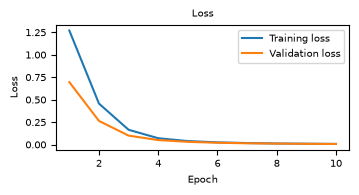

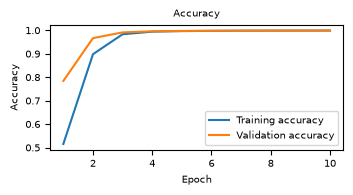

In [57]:
def plotSubplotLearningCurvesFinalArtwork(panelId : str,
                                   isLoss : bool
                                   ):
    
    widthMM, heightMM = getSubplotWidthAndHeight(Exd_F_R3_E2_E_Layout, panelId)
    fig = plotTrainingCurvesFinalArtwork(
                        history=history, 
                        widthInMM=widthMM, 
                        heightInMM=heightMM,
                        isLoss=isLoss,
                        fontSize=7,
            )
    Exd_F_R3_E2_E_Layout[panelId].figure = fig
    

plotSubplotLearningCurvesFinalArtwork(panelId="a", isLoss=True)
plotSubplotLearningCurvesFinalArtwork(panelId="b", isLoss=False)

In [58]:
def plotCMFinalArtwork(
                    model : keras.src.models,
                    panelId : str,
                    XDF : pd.DataFrame,
                    ySeries : pd.Series,                    
                    title : str,
                    fontSize : int = 7
                    # newClassOrder : list[str] = None
    ) -> None:
    ''' 
    TOOD 
    '''
    fig = plotCM(model,
                    XDF, 
                    ySeries,
                    title, 
                    newClassOrder=AEDWIP_chenCMClassOrder
                    )
    
    ax = fig.get_axes()[0]
    
    # clean up the tick labels
    ax.set_xticks(
        ax.get_xticks(),
        labels=[
            # label.get_text().replace("_C", " c")
            label.get_text().replace("_Cancer", "")
            for label in ax.get_xticklabels()
        ],
        fontsize=fontSize,
    )

    ax.set_yticks(
        ax.get_yticks(),
        labels=[
            # label.get_text().replace("_C", " c")
            label.get_text().replace("_Cancer", "")
            for label in ax.get_yticklabels()
        ],
        fontsize=fontSize,
    )
    # plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    # plt.setp(ax.get_xticklabels(), rotation=60, ha='right')

    
    widthMM, heightMM = getSubplotWidthAndHeight(Exd_F_R3_E2_E_Layout, panelId)
    fig.set_size_inches(widthMM / 25.4,  heightMM / 25.4)
    
    # reserve more bottom margin for the x-axis ticks
    fig.subplots_adjust(bottom=0.32)
    fig.tight_layout()
    
    Exd_F_R3_E2_E_Layout[panelId].figure = fig


2026-10-15 15:13:18,442 WARNING 287088127.py plotCMImpl() line:51] [labels                 : ['Colorectal_Cancer', 'Stomach_Cancer', 'Liver_Cancer', 'Lung_Cancer', 'Esophagus_Cancer']]
2026-10-15 15:13:18,444 WARNING 287088127.py plotCMImpl() line:52] [ySeries.cat.categories : Index(['Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer', 'Lung_Cancer',
       'Stomach_Cancer'],
      dtype='str')]


ySeries.cat.categories : Index(['Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer', 'Lung_Cancer',
       'Stomach_Cancer'],
      dtype='str')


2026-10-15 15:13:18,957 WARNING 287088127.py plotCMImpl() line:51] [labels                 : ['Colorectal_Cancer', 'Stomach_Cancer', 'Liver_Cancer', 'Lung_Cancer', 'Esophagus_Cancer']]
2026-10-15 15:13:18,958 WARNING 287088127.py plotCMImpl() line:52] [ySeries.cat.categories : Index(['Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer', 'Lung_Cancer',
       'Stomach_Cancer'],
      dtype='str')]


layout[c].widthMm : 90
layout[c].heightMm : 70
ySeries.cat.categories : Index(['Colorectal_Cancer', 'Esophagus_Cancer', 'Liver_Cancer', 'Lung_Cancer',
       'Stomach_Cancer'],
      dtype='str')
layout[d].widthMm : 90
layout[d].heightMm : 70


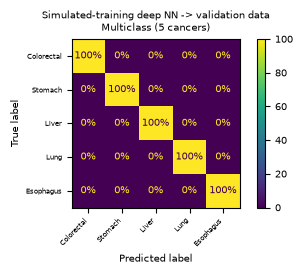

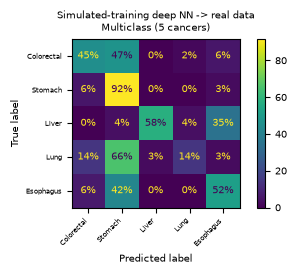

In [59]:
plotCMFinalArtwork(model,
                    "c",
                    XValidationScaledNP,
                    yValidationSeries,
                    title="Simulated-training deep NN -> validation data\nMulticlass (5 cancers)",
                    fontSize=5,
                   )

plotCMFinalArtwork(model,
                    "d",
                     XRealScaledNP,
                    yRealSeries,
                    title='Simulated-training deep NN -> real data\nMulticlass (5 cancers)',
                    fontSize=5,
                   )
    


layout[e].widthMm : 90
layout[e].heightMm : 55


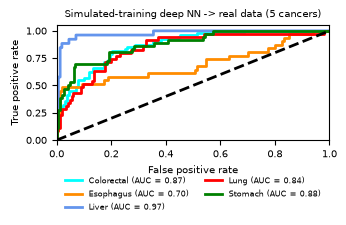

In [60]:
def plotROCFinalArtwork(panelId : str) -> None :
    ''' 
    TODO
    '''
    t = plotROCCurve(
            model=kerasAdapterModel, #model,
            #aedwip labelEncoder=labelEncoder,
            XDF=XRealScaledNP ,
            #y=y,
            ySeries=yRealSeries,
            # title=realROCFigTitle,
            title='Simulated-training deep NN -> real data (5 cancers)',
            #binaryPositiveLabel='Healthy_donor'
            )
    
    rocPlotFig, rocPlotAx, aucDict =t

    widthMM, heightMM = getSubplotWidthAndHeight(Exd_F_R3_E2_E_Layout, panelId)
    rocPlotFig.set_size_inches(widthMM / 25.4,  heightMM / 25.4)
    
        # Reserve space inside the figure for the legend.
    rocPlotFig.subplots_adjust(bottom=0.35)

    rocPlotAx.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.25),
        ncol=2,
        fontsize=6,
        frameon=False,
    )
    
    rocPlotAx.set_xlabel('False positive rate')
    rocPlotAx.set_ylabel('True positive rate')
    
    legend = rocPlotAx.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            text.set_text(text.get_text().replace("_Cancer", ""))
    
    rocPlotFig.subplots_adjust(
        left=0.20,     # Space for y-axis tick labels and axis label
        bottom=0.35,   # Space for x-axis label and legend
        right=0.97,
        top=0.88,
    )
    
    Exd_F_R3_E2_E_Layout[panelId].figure = rocPlotFig

    
plotROCFinalArtwork("e")

In [61]:
def plotSensitityFinalArtwork(panelId : str, fontSize : int=7):
    ''' 
    TODO
    '''
    realSenitivityAt90PercentSpecificityDF= realSenitivityAtSpecificityDF.loc[:, ['diagnosis', 'Sensitivity (TPR)']]
    df = realSenitivityAt90PercentSpecificityDF.copy()
    df['Sensitivity (TPR)'] = df['Sensitivity (TPR)'].round(2)
    # df.rename(columns={'Sensitivity (TPR)' :'Sensitivity @ 90% specificity'}, inplace=True)
    df.rename(columns={'diagnosis' : 'Diagnosis'}, inplace=True)
    # "Stomach_Cancer" -> "Stomach cancer"
    df['Diagnosis'] = df['Diagnosis'].str.replace(r'_C', ' c', regex=False)

    display( df )

    t = Path(f'{imgPanelOutDir}/manuscript/realSenitivityAt90PercentSpecificity.png')
    realSenitivityAt90PercentSpecificityDFPath = t
    realSenitivityAt90PercentSpecificityDFPath.parent.mkdir(parents=True, exist_ok=True)
    fig = saveDataFrameImage(df,realSenitivityAt90PercentSpecificityDFPath, showIndex=False )
    
    ax = fig.get_axes()[0]
    for table in ax.tables: # there is only 1 table
        table.auto_set_font_size(False)
        table.set_fontsize(fontSize)
        table[(0, 1)].get_text().set_text('Sensitivity @ 90% specificity')
        
    # move the table to create space between the figure subplot id and the table
    for ax in fig.axes:
        if len(ax.tables) > 0:
            pos = ax.get_position()

            shift = 0.10 * pos.width

            ax.set_position([
                pos.x0 + shift,      # Move right
                pos.y0,              # Keep vertical position
                pos.width - shift,   # Narrow; keep right edge fixed
                pos.height,
            ])  

    widthMM, heightMM = getSubplotWidthAndHeight(Exd_F_R3_E2_E_Layout, panelId)
    fig.set_size_inches(widthMM / 25.4,  heightMM / 25.4)
    
    
    Exd_F_R3_E2_E_Layout[panelId].figure = fig
    
plotSensitityFinalArtwork("f", fontSize=6)

,Diagnosis,Sensitivity (TPR)
0,Colorectal cancer,0.47
1,Esophagus cancer,0.52
2,Liver cancer,0.62
3,Lung cancer,0.22
4,Stomach cancer,0.21


2026-10-15 15:13:20,143 WARNING plotUtilities.py saveDataFrameImage() line:204] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/panel/manuscript/realSenitivityAt90PercentSpecificity.png]
2026-10-15 15:13:20,272 WARNING plotUtilities.py saveDataFrameImage() line:207] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/panel/manuscript/realSenitivityAt90PercentSpecificity.pdf]


layout[f].widthMm : 80
layout[f].heightMm : 40


Layout valid: 180 × 185 mm total; panels occupy extents of 180 × 185 mm.


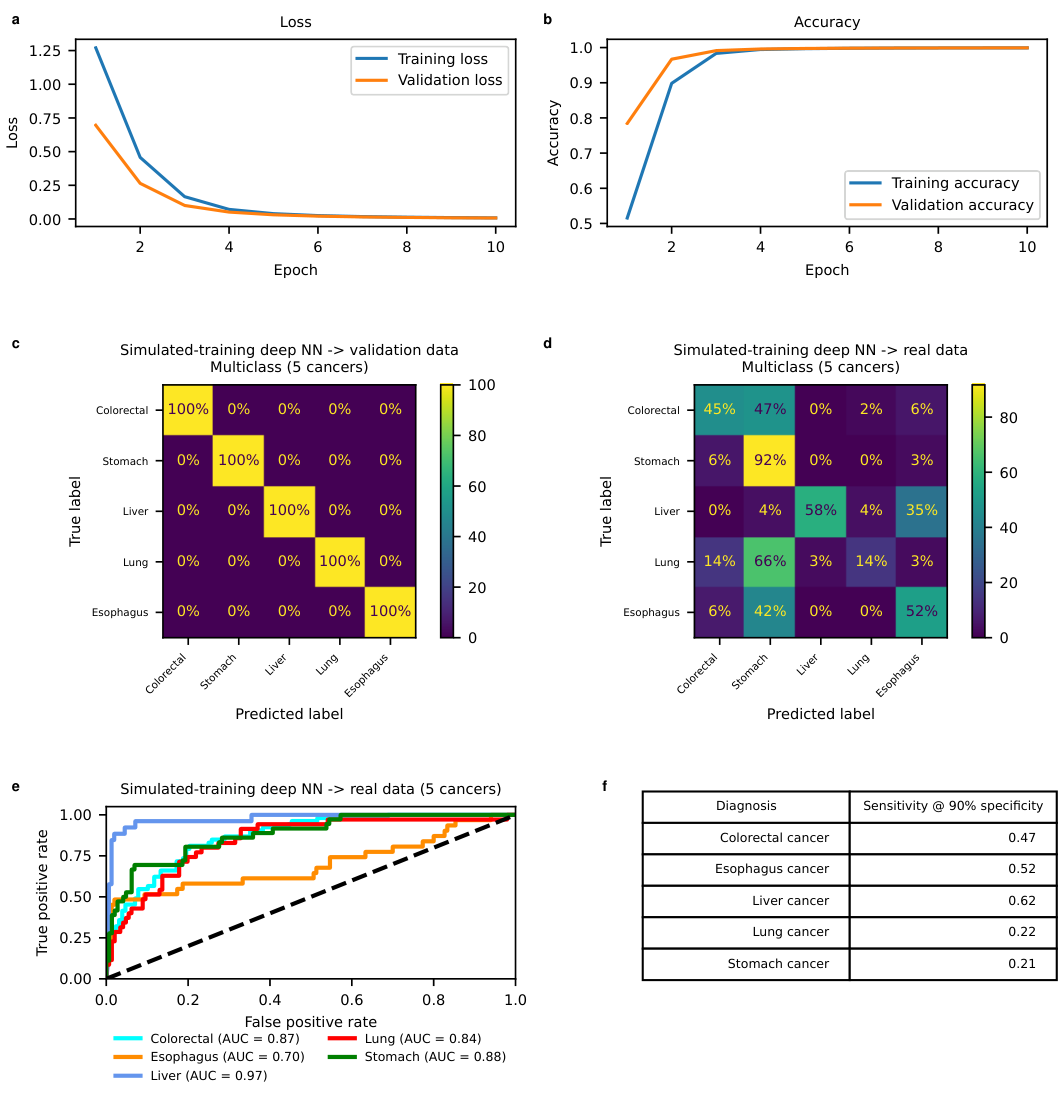

saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/deepMultiClassifiers.out/img/panel/manuscript/Exd_F_R3_E2_E_deepPanel.pdf


In [65]:
Exd_F_R3_E2_E_OutputStem = Path(f'{imgPanelOutDir}/manuscript/Exd_F_R3_E2_E_deepPanel') 
Exd_F_R3_E2_E_OutputStem.mkdir(parents=True, exist_ok=True)

pdfPath, pngPath = combineFiguresLayout(
    panels=Exd_F_R3_E2_E_Layout,
    outputStem=Exd_F_R3_E2_E_OutputStem,
    widthMm=180,
    heightMm=185,
    addPanelLabels=True,
    labelFontSize=7,
    legendFigure=None,
    legendHeightMm=0,
    maxWidthMm=180,
    maxHeightMm=185,
    pngDpi=600,
)

displayPDFInNotebook(pdfPath)
print(f'saved : {pdfPath}')

In [63]:
logger.warning("END NOTEBOOK")
elapsed = time.time() - notebook_start_time
hours, rem = divmod(elapsed, 3600)
minutes, seconds = divmod(rem, 60)
print(f"✅ Notebook completed in {int(hours)}h {int(minutes)}m {seconds:.1f}s.")

2026-10-15 15:13:22,241 WARNING 2279843384.py <module>() line:1] [END NOTEBOOK]


✅ Notebook completed in 0h 2m 22.4s.
